# 04 — Baselines não supervisionados
Clusterização **sem** uso de rótulos; associação com grupo (CTR/TCM) e sexo só **a posteriori**.
Granularidades:
- **Participante** (n=38, mediana das janelas) — alinhada à pergunta do TCC.
- **Participante — distribuição das janelas** (`participante_distrib`): cada pessoa descrita pela forma e dinâmica das
  suas janelas z-normalizadas, não pela média (remove o "efeito indivíduo" sem zerar a informação de nível sujeito).
- **Janela** (5 s) — com número de janelas **balanceado por participante** (o RAB2 dos CTR é ~2× mais longo que o dos TCM;
  sem balancear, CTR domina os clusters) e voto majoritário para voltar ao nível participante.

Tabela final (`reports/04_baselines.csv`) é o placar de referência para os métodos do TCC (ex.: features latentes).
19 canais de escalpo (sem A1/A2). Protocolo em `src/clustering.py` (reusado no notebook 07).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from src.data_io import PROCESSED_DIR, ROOT
from src.features import subject_distribution_features
from src.evaluation import internal_metrics, external_metrics
from src.clustering import to_pca, balance_windows, k_sweep, best_k as pick_k, evaluate

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0

feat_w = pd.read_parquet(PROCESSED_DIR / "features_windows.parquet")
feat_s = pd.read_parquet(PROCESSED_DIR / "features_subjects.parquet")
ID_COLS = ["subject", "group", "sex", "window"]
FEATS = [c for c in feat_w.columns if c not in ID_COLS]
print(feat_w.shape, feat_s.shape)

(2656, 384) (38, 383)


## Representações
StandardScaler → PCA retendo 95% da variância. Variante nível janela com z-score **dentro** de cada participante
(remove o "efeito indivíduo"; atenção: também remove diferenças estáveis entre grupos, útil para estados afetivos).

In [2]:
Xs = to_pca(feat_s[FEATS])
print("participante: componentes PCA =", Xs.shape[1])

N_PER_SUBJ = 40
bal = balance_windows(feat_w, N_PER_SUBJ)
print("janelas balanceadas:", len(bal), "| por grupo:", bal.group.value_counts().to_dict())
Xw = to_pca(bal[FEATS])
Xw_subj = to_pca(bal.groupby("subject")[FEATS].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9)))
print("janela: componentes PCA =", Xw.shape[1], "| janela z-sujeito:", Xw_subj.shape[1])

participante: componentes PCA = 25
janelas balanceadas: 1346 | por grupo: {'CTR': 780, 'TCM': 566}


janela: componentes PCA = 110 | janela z-sujeito: 150


### Distribuição das janelas por participante
Após z-score dentro do participante, média=0 e std=1 para todos — então o que descreve a pessoa é a **forma**
(p10, p90, assimetria, curtose) e a **dinâmica** (autocorrelação lag-1 entre janelas consecutivas; há 1 s de
sobreposição entre janelas vizinhas, o que infla um pouco o valor para todos igualmente), mais a variabilidade
bruta (IQR). Estatísticas calculadas nas primeiras 40 janelas retidas (duração é confundida com grupo) e agregadas
por família de feature (média entre canais). Participantes com < 15 janelas ficam de fora (estimativas instáveis).

In [3]:
MIN_WINDOWS = 15
dist_all = subject_distribution_features(feat_w, FEATS, max_windows=N_PER_SUBJ)
excl = dist_all[dist_all.n_windows_used < MIN_WINDOWS]
print("excluídos (<%d janelas):" % MIN_WINDOWS, excl[["subject", "group", "n_windows_used"]].to_dict("records"))
dist_s = dist_all[dist_all.n_windows_used >= MIN_WINDOWS].reset_index(drop=True)
DIST_FEATS = [c for c in dist_s.columns if "__" in c]
dist_s[DIST_FEATS] = dist_s[DIST_FEATS].fillna(dist_s[DIST_FEATS].median())
Xd = to_pca(dist_s[DIST_FEATS])
print(f"participante_distrib: n={len(dist_s)} ({dist_s.group.value_counts().to_dict()}), "
      f"{len(DIST_FEATS)} features -> {Xd.shape[1]} componentes PCA")

excluídos (<15 janelas): [{'subject': 'P23', 'group': 'CTR', 'n_windows_used': 8}, {'subject': 'P15', 'group': 'TCM', 'n_windows_used': 10}, {'subject': 'P27', 'group': 'TCM', 'n_windows_used': 8}]
participante_distrib: n=35 ({'CTR': 20, 'TCM': 15}), 120 features -> 23 componentes PCA


## Algoritmos
`k` fixo em 2 para comparar com CTR/TCM, e varredura k=2..8 para escolher pelo silhouette (visão puramente não supervisionada).
DBSCAN usa `eps` pelo joelho da distância ao k-ésimo vizinho; HDBSCAN escolhe o nº de clusters sozinho.

Implementação: `src/clustering.algorithms` / `density_algorithms`.

## Escolha de k (k-means, GMM-BIC)

{'participante': 3,
 'participante_distrib': 2,
 'janela': 3,
 'janela_zsujeito': 2}

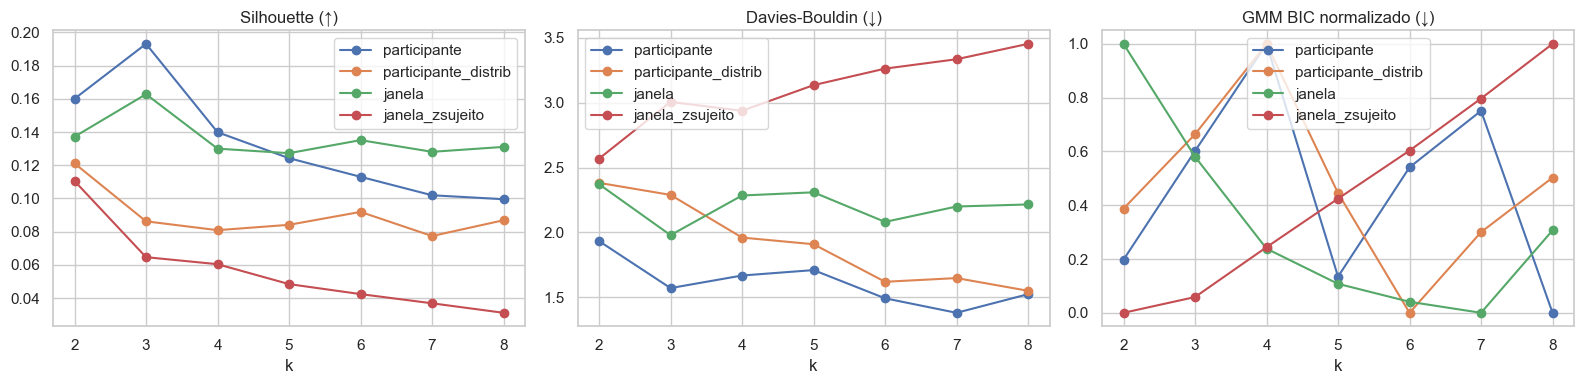

In [4]:
sweeps = {"participante": k_sweep(Xs), "participante_distrib": k_sweep(Xd),
          "janela": k_sweep(Xw), "janela_zsujeito": k_sweep(Xw_subj)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, sw in sweeps.items():
    axes[0].plot(sw.k, sw.silhouette, marker="o", label=name)
    axes[1].plot(sw.k, sw.davies_bouldin, marker="o", label=name)
    axes[2].plot(sw.k, (sw.gmm_bic - sw.gmm_bic.min()) / (sw.gmm_bic.max() - sw.gmm_bic.min() + 1e-9), marker="o", label=name)
for ax, t in zip(axes, ["Silhouette (↑)", "Davies-Bouldin (↓)", "GMM BIC normalizado (↓)"]):
    ax.set_title(t); ax.set_xlabel("k"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "04_k_sweep.png", dpi=120)
best_k = {n: pick_k(sw) for n, sw in sweeps.items()}
best_k

## Rodada de baselines

In [5]:
results, labels_store = [], {}
for k in sorted({2, best_k["participante"]}):
    r, l = evaluate("participante", Xs, feat_s, k); results += r; labels_store[("participante", k)] = l
for k in sorted({2, best_k["participante_distrib"]}):
    r, l = evaluate("participante_distrib", Xd, dist_s, k); results += r; labels_store[("participante_distrib", k)] = l
for lvl, X in [("janela", Xw), ("janela_zsujeito", Xw_subj)]:
    for k in sorted({2, best_k[lvl]}):
        r, l = evaluate(lvl, X, bal, k, subjects=bal.subject.to_numpy()); results += r; labels_store[(lvl, k)] = l

res = pd.DataFrame(results)
res.to_csv(ROOT / "reports" / "04_baselines.csv", index=False)
cols = ["level", "algo", "k_param", "n_clusters", "noise_frac", "silhouette", "davies_bouldin", "stability_ARI",
        "grupo_ARI", "grupo_NMI", "grupo_purity", "grupo_p_assoc", "grupo_voto_ARI", "grupo_voto_p_assoc",
        "sexo_ARI", "subject_ARI"]
res[[c for c in cols if c in res]].round(3)

C:\Users\Consultor.NB-BHN-9950\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


C:\Users\Consultor.NB-BHN-9950\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


C:\Users\Consultor.NB-BHN-9950\Desktop\artifacts\mestrado\tcc\src\evaluation.py:27: RuntimeWarning: invalid value encountered in scalar divide
  return ct.max(axis=1).sum() / ct.values.sum()


,level,algo,k_param,n_clusters,noise_frac,silhouette,davies_bouldin,stability_ARI,grupo_ARI,grupo_NMI,grupo_purity,grupo_p_assoc,grupo_voto_ARI,grupo_voto_p_assoc,sexo_ARI,subject_ARI
0,participante,random,2,2,0.000,-0.022,9.006,NaN,-0.001,0.014,0.579,0.509,NaN,NaN,0.015,NaN
1,participante,kmeans,2,2,0.000,0.160,1.934,0.771,-0.025,0.002,0.553,1.000,NaN,NaN,-0.021,NaN
2,participante,agglo_ward,2,2,0.000,0.269,1.260,0.488,-0.016,0.001,0.553,1.000,NaN,NaN,0.053,NaN
3,participante,gmm,2,2,0.000,0.269,1.260,0.382,-0.016,0.001,0.553,1.000,NaN,NaN,0.053,NaN
4,participante,spectral,2,2,0.000,0.155,1.917,NaN,-0.016,0.006,0.553,0.743,NaN,NaN,-0.024,NaN
5,participante,dbscan,auto,1,0.026,NaN,NaN,NaN,0.012,0.053,0.579,0.447,NaN,NaN,-0.033,NaN
6,participante,hdbscan,auto,0,1.000,NaN,NaN,NaN,0.000,0.000,0.553,NaN,NaN,NaN,0.000,NaN
7,participante,random,3,3,0.000,-0.030,5.617,NaN,-0.007,0.024,0.579,0.447,NaN,NaN,-0.020,NaN
8,participante,kmeans,3,3,0.000,0.193,1.572,0.953,-0.028,0.005,0.553,0.856,NaN,NaN,-0.000,NaN
9,participante,agglo_ward,3,3,0.000,0.179,1.637,0.766,-0.034,0.001,0.553,0.957,NaN,NaN,0.016,NaN


## Leitura rápida
- `random` é o piso: ARI/NMI ≈ 0. Um método só "acha" diagnóstico se superar claramente esse piso **e** p_assoc < 0,05.
- Pureza tem piso = proporção da classe majoritária (21/38 ≈ 0,55).
- `subject_ARI` alto no nível janela = clusters reproduzem participantes (efeito indivíduo), não grupos.
- `sexo_*` serve de controle: se clusters associam mais a sexo do que a grupo, há confundidor.

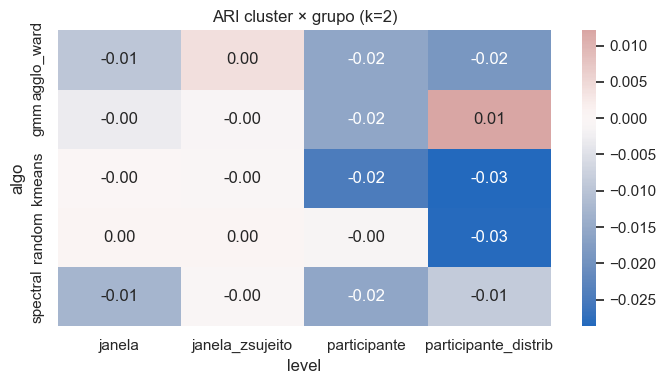

In [6]:
pivot = res[res.k_param.astype(str) == "2"].pivot_table(index="algo", columns="level", values="grupo_ARI")
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("ARI cluster × grupo (k=2)")
fig.tight_layout(); fig.savefig(FIG / "04_ari_grupo.png", dpi=120)

## Tabelas de contingência — nível participante, k=2

In [7]:
for name, lab in labels_store[("participante", 2)].items():
    ct = pd.crosstab(pd.Series(lab, name="cluster"), [feat_s.group.rename("grupo")])
    print(f"--- {name}"); display(ct)

--- random


grupo,CTR,TCM
cluster,,
0,7,8
1,14,9


--- kmeans


grupo,CTR,TCM
cluster,,
0,10,9
1,11,8


--- agglo_ward


...

grupo,CTR,TCM
cluster,,
0,8,8
1,13,9


--- dbscan


grupo,CTR,TCM
cluster,,
-1,0,1
0,21,16


--- hdbscan


grupo,CTR,TCM
cluster,,
-1,21,17


## Distribuição das janelas — contingência, confundidores e o que diferencia os clusters
Checagem: o nº de janelas usadas não deve explicar os clusters (senão estaríamos clusterizando duração).

--- kmeans


grupo,CTR,TCM
cluster,,
0,9,6
1,11,9


  n_janelas por cluster (Mann-Whitney p): 0.108
--- agglo_ward


grupo,CTR,TCM
cluster,,
0,16,12
1,4,3


  n_janelas por cluster (Mann-Whitney p): 0.436
--- gmm


grupo,CTR,TCM
cluster,,
0,14,8
1,6,7


  n_janelas por cluster (Mann-Whitney p): 0.477
Spearman(PC1, n_janelas) = 0.457 | Spearman(PC2, n_janelas) = 0.143


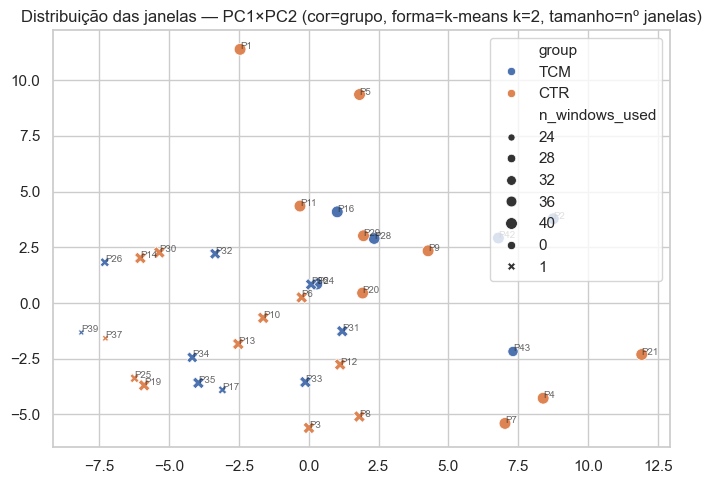

In [8]:
from scipy import stats as sstats
for name in ["kmeans", "agglo_ward", "gmm"]:
    lab = labels_store[("participante_distrib", 2)][name]
    print(f"--- {name}"); display(pd.crosstab(pd.Series(lab, name="cluster"), dist_s.group.rename("grupo")))
    print("  n_janelas por cluster (Mann-Whitney p):",
          round(sstats.mannwhitneyu(dist_s.n_windows_used[lab == 0], dist_s.n_windows_used[lab == 1]).pvalue, 3))

Zd = PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(dist_s[DIST_FEATS]))
print("Spearman(PC1, n_janelas) =", round(sstats.spearmanr(Zd[:, 0], dist_s.n_windows_used)[0], 3),
      "| Spearman(PC2, n_janelas) =", round(sstats.spearmanr(Zd[:, 1], dist_s.n_windows_used)[0], 3))
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=Zd[:, 0], y=Zd[:, 1], hue=dist_s.group, style=labels_store[("participante_distrib", 2)]["kmeans"],
                size=dist_s.n_windows_used, ax=ax)
for i, s_ in enumerate(dist_s.subject):
    ax.annotate(s_, Zd[i], fontsize=7, alpha=0.7)
ax.set_title("Distribuição das janelas — PC1×PC2 (cor=grupo, forma=k-means k=2, tamanho=nº janelas)")
fig.tight_layout(); fig.savefig(FIG / "04_distrib_pca.png", dpi=120)

In [9]:
# Estatísticas mais diferentes entre os clusters do k-means (descritivo; ajuda a interpretar o que o cluster captura)
lab = labels_store[("participante_distrib", 2)]["kmeans"]
diff = pd.DataFrame({c: [dist_s.loc[lab == 0, c].median(), dist_s.loc[lab == 1, c].median(),
                         sstats.mannwhitneyu(dist_s.loc[lab == 0, c], dist_s.loc[lab == 1, c]).pvalue]
                     for c in DIST_FEATS}, index=["mediana_c0", "mediana_c1", "p"]).T.sort_values("p")
diff.head(12).round(3)

,mediana_c0,mediana_c1,p
p10__rel_beta,-0.956,-1.112,0.0
skew__rel_beta,1.525,0.639,0.0
skew__hjorth_mobility,0.791,0.132,0.0
kurt__rel_beta,3.185,0.488,0.0
p10__rel_gamma,-0.867,-1.023,0.0
skew__rel_gamma,2.002,1.031,0.0
p10__hjorth_mobility,-1.093,-1.183,0.0
skew__rel_delta,-0.429,0.015,0.0
iqr_raw__ratio_theta_beta,3.242,1.268,0.0
iqr_raw__ratio_theta_alpha,2.311,1.185,0.0


## Dendrograma (Ward) nível participante

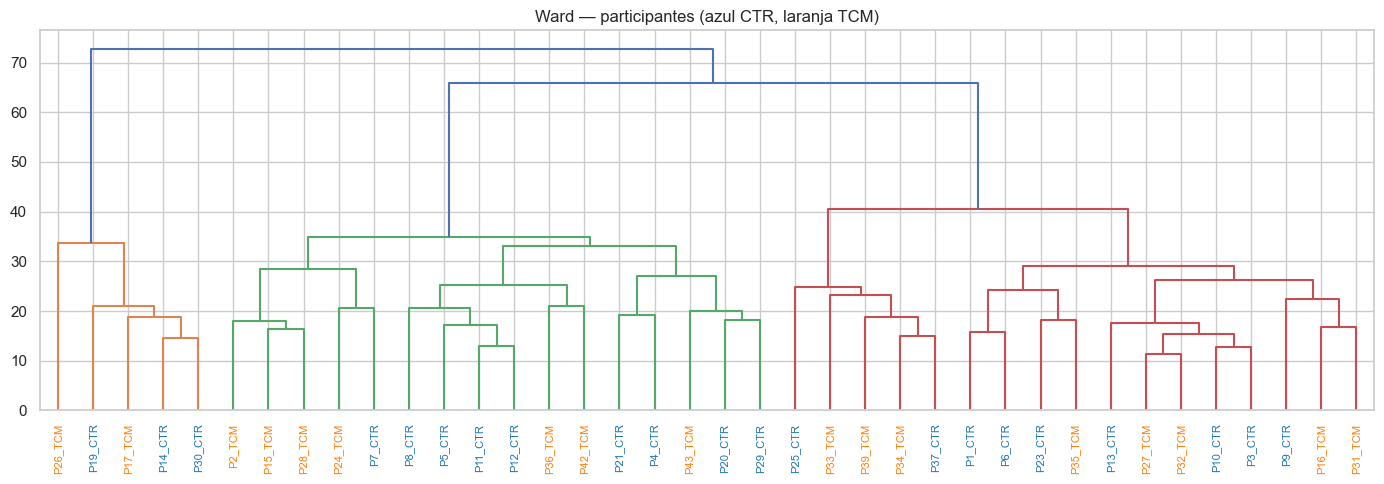

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram
Lk = linkage(Xs, method="ward")
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Lk, labels=(feat_s.subject + "_" + feat_s.group).tolist(), leaf_rotation=90, ax=ax)
for t in ax.get_xticklabels():
    t.set_color("tab:orange" if t.get_text().endswith("TCM") else "tab:blue")
ax.set_title("Ward — participantes (azul CTR, laranja TCM)")
fig.tight_layout(); fig.savefig(FIG / "04_dendrograma.png", dpi=120)

## Afeto (RAB2)
Quando `polarity_rab2`/`affect_rab2` estiverem em `data/metadata.csv`, repetir `external_metrics(meta.affect_rab2, labels)`.
Com 34/3/2 (tese), usar só descrição (em qual cluster caem os 5 não-positivos) — métricas globais serão dominadas pela classe positiva.